# Olist 电商数据分析

先运行 `sql/02_order_wide.sql` 和 `sql/03_user_summary.sql`，再打开本 Notebook。


In [13]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path          # ← 补这一行

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']   # 不设中文会变方块
plt.rcParams['axes.unicode_minus'] = False

root = Path.cwd()
if not (root / 'run_sql.py').exists():
    root = root.parent          # 内核在 notebooks\ 时回上一级
DB = root / 'olist.duckdb'
assert DB.exists(), f'库文件不存在：{DB}'   # 别让它静默新建空库
con = duckdb.connect(str(DB))
print(con.sql('SHOW TABLES').df())          # 留着当验收






           name
0    order_wide
1  user_summary


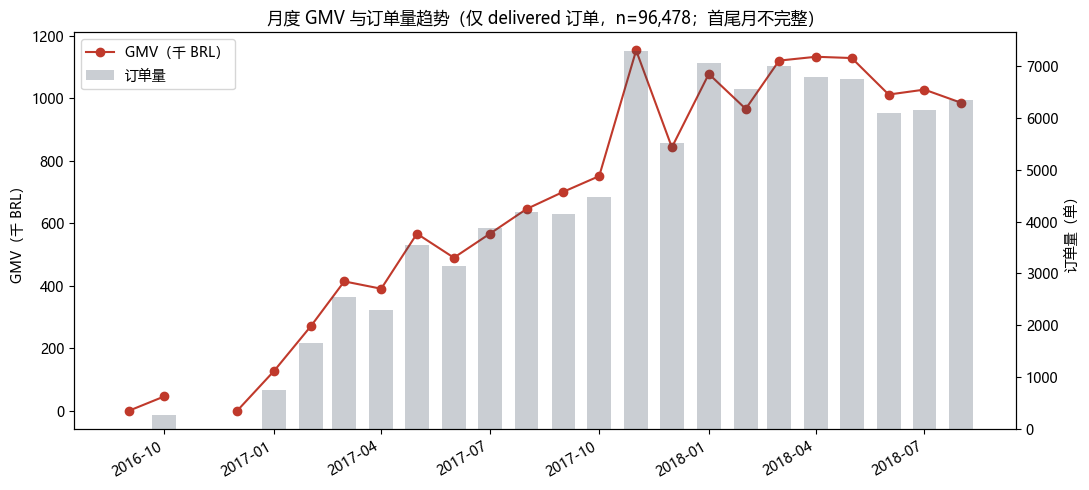

In [14]:
df = con.sql("""
SELECT DATE_TRUNC('month', purchase_ts) AS month,
       COUNT(DISTINCT order_id) AS orders,
       SUM(COALESCE(item_revenue,0) + COALESCE(freight_value,0)) AS gmv
FROM order_wide
WHERE order_status = 'delivered'
GROUP BY 1 ORDER BY 1
""").df()

df['month'] = pd.to_datetime(df['month'])
df = df.set_index('month').resample('MS').asfreq()   # 补齐缺失月份

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(df.index, df['gmv']/1000, marker='o', color='#C0392B', label='GMV（千 BRL）')
ax1.set_ylabel('GMV（千 BRL）')
ax2 = ax1.twinx()
ax2.bar(df.index, df['orders'], width=20, alpha=0.25, color='#2C3E50', label='订单量')
ax2.set_ylabel('订单量（单）')
ax1.set_title('月度 GMV 与订单量趋势（仅 delivered 订单，n=96,478；首尾月不完整）')
fig.autofmt_xdate()
l1, b1 = ax1.get_legend_handles_labels()
l2, b2 = ax2.get_legend_handles_labels()
ax1.legend(l1+l2, b1+b2, loc='upper left')
plt.tight_layout()
plt.savefig('../reports/figures/01_monthly_gmv.png', dpi=150, bbox_inches='tight')
plt.show()

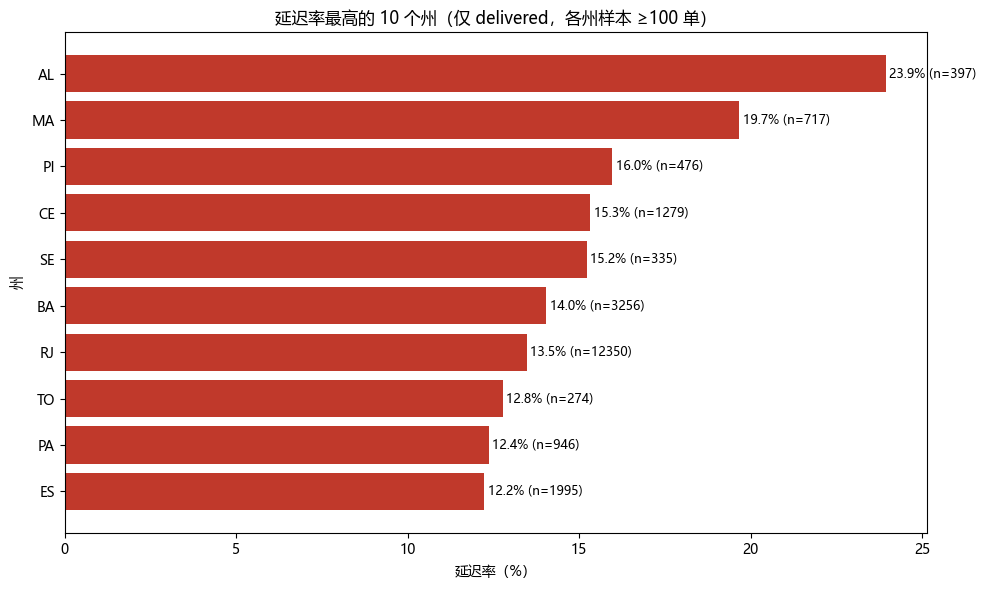

In [15]:
st = con.sql("""
SELECT customer_state, COUNT(*) AS orders, AVG(late_flag) AS late_rate
FROM order_wide
WHERE order_status = 'delivered'
GROUP BY 1 HAVING COUNT(*) >= 100
ORDER BY late_rate DESC LIMIT 10
""").df().sort_values('late_rate')

plt.figure(figsize=(10, 6))
plt.barh(st['customer_state'], st['late_rate']*100, color='#C0392B')
plt.xlabel('延迟率（%）'); plt.ylabel('州')
plt.title('延迟率最高的 10 个州（仅 delivered，各州样本 ≥100 单）')
for i, (v, n) in enumerate(zip(st['late_rate']*100, st['orders'])):
    plt.text(v + 0.1, i, f'{v:.1f}% (n={n})', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('../reports/figures/02_late_rate_by_state.png', dpi=150, bbox_inches='tight')
plt.show()


## 下一步

1. 数据质量检查
2. 经营与履约分析
3. 评分与复购分析
4. 导出图表到 `reports/figures/`
